# Notebook 05 — Statistical Segment Validation & Temporal Prediction Foundation

**Project:** Customer Segmentation and Retention Analysis Using Machine Learning and Statistical Modelling  
**Dataset:** Online Retail II — Year 1 only (December 2009 – December 2010)  
**Author:** OELP Project  

---

## Purpose

This notebook serves as the **bridge** between completed segmentation (Notebooks 01–04) and future predictive modelling (Notebooks 06+). It accomplishes two things:

1. **Statistically validates** whether the two K-Means customer segments from Notebook 04 show meaningfully different future purchasing behaviour — using a leakage-free historical cutoff.
2. **Establishes a reusable, leakage-free temporal prediction framework** — documented cutoffs, feature extraction, target construction, and censoring rules — ready for downstream notebooks.

### Critical design constraint — no temporal leakage

Notebook 04's full-year RFM cluster labels were fitted using data through December 2010. Those labels **cannot** be used to predict purchases that occurred earlier in the year — doing so would leak future information into historical predictors. Instead, we:

- Select a historical cutoff date that leaves sufficient future observations.
- Reconstruct RFM features and refit log-transformations, scaling, and K-Means using **only pre-cutoff data**.
- Assign segment labels from the historical fit.
- Measure future purchasing outcomes **only** from post-cutoff records.

### Inactivity threshold

Notebook 03 established an empirical P90 inter-purchase gap threshold of **101.9 days**, used as a *descriptive* at-risk flag only. It is **not** ground-truth churn. For historical evaluation, we recompute an equivalent threshold from training-period observations only.


## 0. Environment setup

In [1]:
import sys, os, json, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from scipy import stats
from scipy.stats import mannwhitneyu, chi2_contingency, fisher_exact
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import lifelines
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test

# ---------------------------------------------------------------------------
# Portable path resolution: works from both /notebooks and project root
# ---------------------------------------------------------------------------
_nb_dir = os.path.abspath(os.getcwd())
# Candidates: notebook's parent (repo root), or cwd itself if run from root
_candidates = [
    os.path.join(_nb_dir, '..', 'src'),  # running from notebooks/
    os.path.join(_nb_dir, 'src'),         # running from project root
]
_src_path = None
for _cand in _candidates:
    _mod_file = os.path.join(_cand, 'temporal_framework.py')
    if os.path.isfile(_mod_file):
        _src_path = os.path.abspath(_cand)
        _tf_file  = os.path.abspath(_mod_file)
        break

if _src_path is None:
    raise ImportError(
        'Cannot locate src/temporal_framework.py. '
        'Run this notebook from the project root or the notebooks/ directory.'
    )

if _src_path not in sys.path:
    sys.path.insert(0, _src_path)

import importlib.util as _ilu
_spec = _ilu.spec_from_file_location('temporal_framework', _tf_file)
tf    = _ilu.module_from_spec(_spec)
_spec.loader.exec_module(tf)
print(f'temporal_framework loaded from: {_tf_file}')

# Output paths — resolved portably
_proj_root = os.path.abspath(os.path.join(_src_path, '..'))
DATA_PROC   = os.path.join(_proj_root, 'data', 'processed')
TEMPORAL_DIR = os.path.join(DATA_PROC, 'temporal')
os.makedirs(TEMPORAL_DIR, exist_ok=True)

# Plotting style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('Set2')

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print(f'lifelines version  : {lifelines.__version__}')
print(f'Project root       : {_proj_root}')
print(f'Temporal output dir: {TEMPORAL_DIR}')


temporal_framework loaded from: C:\Manthan\Customer_segmentation_retention\main_project\src\temporal_framework.py
lifelines version  : 0.30.3
Project root       : C:\Manthan\Customer_segmentation_retention\main_project
Temporal output dir: C:\Manthan\Customer_segmentation_retention\main_project\data\processed\temporal


---
## 1. Data preparation — order-level foundation

We load the cleaned transaction file (from Notebook 01's cleaning pipeline) and aggregate individual purchase lines to the order (invoice) level.  
Rules preserved from earlier notebooks:
- Cancellation invoices (C-prefix) are excluded from purchase orders.
- Administrative test accounts 14103 and 14827 are excluded.
- Gross revenue = Σ(Quantity × Price) per invoice.

In [2]:
# Load cleaned transactions
cleaned_path = os.path.join(DATA_PROC, 'online_retail_cleaned_data.csv')
raw = pd.read_csv(cleaned_path)
raw['InvoiceDate'] = pd.to_datetime(raw['InvoiceDate'])

ADMIN_EXCLUDE = {14103, 14827}

# Separate purchases from cancellations
purchases_raw = raw[~raw['Invoice'].str.startswith('C')].copy()
purchases_raw = purchases_raw[~purchases_raw['Customer ID'].isin(ADMIN_EXCLUDE)]
purchases_raw['LineRevenue'] = purchases_raw['Quantity'] * purchases_raw['Price']

print(f'Raw transactions loaded          : {len(raw):,}')
print(f'Purchase lines (non-cancellation): {len(purchases_raw):,}')
print(f'Date range                       : {purchases_raw["InvoiceDate"].min()} '
      f'to {purchases_raw["InvoiceDate"].max()}')
print(f'Unique customers                 : {purchases_raw["Customer ID"].nunique():,}')
print(f'Unique invoices                  : {purchases_raw["Invoice"].nunique():,}')


Raw transactions loaded          : 410,763
Purchase lines (non-cancellation): 400,945
Date range                       : 2009-12-01 07:45:00 to 2010-12-09 20:01:00
Unique customers                 : 4,312
Unique invoices                  : 19,213


In [3]:
# Build order-level dataset
orders = (
    purchases_raw
    .groupby(['Customer ID', 'Invoice'], as_index=False)
    .agg(
        PurchaseDate=('InvoiceDate', 'min'),
        GrossRevenue=('LineRevenue', 'sum'),
    )
)
orders = orders.sort_values(['Customer ID', 'PurchaseDate']).reset_index(drop=True)

# Dataset boundaries (using fractional-second precision for censoring)
DATASET_START = orders['PurchaseDate'].min()
DATASET_END   = orders['PurchaseDate'].max()
DATASET_SPAN  = (DATASET_END - DATASET_START).days

print(f'Order-level rows   : {len(orders):,}')   # expected: 19,213
print(f'Unique customers   : {orders["Customer ID"].nunique():,}')
print(f'Unique invoices    : {orders["Invoice"].nunique():,}')
print(f'Dataset start      : {DATASET_START}')
print(f'Dataset end        : {DATASET_END}')
print(f'Dataset span       : {DATASET_SPAN} days')
print(f'Total gross revenue: £{orders["GrossRevenue"].sum():,.0f}')
print(f'Revenue per order  : £{orders["GrossRevenue"].mean():,.2f} (mean)')

# Save order-level dataset
orders.to_csv(os.path.join(TEMPORAL_DIR, 'orders.csv'), index=False)
print('\nSaved: data/processed/temporal/orders.csv')


Order-level rows   : 19,213
Unique customers   : 4,312
Unique invoices    : 19,213
Dataset start      : 2009-12-01 07:45:00
Dataset end        : 2010-12-09 20:01:00
Dataset span       : 373 days
Total gross revenue: £8,798,234
Revenue per order  : £457.93 (mean)



Saved: data/processed/temporal/orders.csv


In [4]:
# Integrity checks on order-level data
assert orders['Invoice'].nunique() == len(orders), 'Duplicate invoices in order dataset'
assert (orders['GrossRevenue'] >= 0).all(), 'Negative gross revenue found'
assert orders['Customer ID'].isin(ADMIN_EXCLUDE).sum() == 0, 'Admin accounts found'
assert (~orders['Invoice'].str.startswith('C')).all(), 'Cancellation invoices found'
print('✓ All order-level integrity checks passed.')

✓ All order-level integrity checks passed.


---
## 2. Temporal prediction framework — cutoff selection and split protocol

### Descriptive analysis vs predictive modeling splits

This framework serves two distinct needs with strict leakage controls:

1. **Descriptive Segment Validation (Sections 5–9)**: Uses **Cutoff B (2010-08-01)** as the single primary historical boundary to compare the two segments and the P90 threshold. Each customer has a single observation for standard two-group inference.
2. **Outcome-Matured Predictive Splits (Section 10, for Notebook 06+)**: When training predictive models across temporal splits, **training outcomes must be fully mature before the validation cutoff**, and validation outcomes must be mature before the test cutoff.

Because different forecast horizons ($H \in \{30, 60, 90\}$ days) require different follow-up windows, a single fixed cutoff sequence cannot be outcome-matured for all horizons. We therefore implement **horizon-specific chronological splits**:

| Horizon | Split | Cutoff Date | Target Window Ends | Maturity Before Next Cutoff | Eligible Customers |
|---|---|---|---|---|---|
| **30d** | TRAIN | 2010-06-01 | 2010-07-01 | Matures 31d before VAL (2010-08-01) | 2,703 |
| | VAL | 2010-08-01 | 2010-08-31 | Matures 10d before TEST (2010-09-10) | 3,159 |
| | TEST | 2010-09-10 | 2010-10-10 | Fully observable ($\le$ 2010-12-09) | 3,373 |
| **60d** | TRAIN | 2010-05-01 | 2010-06-30 | Matures 1d before VAL (2010-07-01) | 2,449 |
| | VAL | 2010-07-01 | 2010-08-30 | Matures 11d before TEST (2010-09-10) | 2,973 |
| | TEST | 2010-09-10 | 2010-11-09 | Fully observable ($\le$ 2010-12-09) | 3,373 |
| **90d** | TRAIN | 2010-03-01 | 2010-05-30 | Matures 2d before VAL (2010-06-01) | 1,712 |
| | VAL | 2010-06-01 | 2010-08-30 | Matures 11d before TEST (2010-09-10) | 2,703 |
| | TEST | 2010-09-10 | 2010-12-09 | Fully observable ($\le$ 2010-12-09 20:01) | 3,373 |

**Strict Leakage Guarantee for Modeling:** Preprocessing (StandardScaler and historical KMeans clustering) is fit **strictly on TRAIN** for each horizon, and then applied to transform VAL and TEST without re-fitting.


Horizon observability check:
  Cutoff A (2010-06-01) + 30d → 2010-07-01 ✓
  Cutoff A (2010-06-01) + 60d → 2010-07-31 ✓
  Cutoff A (2010-06-01) + 90d → 2010-08-30 ✓
  Cutoff B (2010-08-01) + 30d → 2010-08-31 ✓
  Cutoff B (2010-08-01) + 60d → 2010-09-30 ✓
  Cutoff B (2010-08-01) + 90d → 2010-10-30 ✓
  Cutoff C (2010-09-10) + 30d → 2010-10-10 ✓
  Cutoff C (2010-09-10) + 60d → 2010-11-09 ✓
  Cutoff C (2010-09-10) + 90d → 2010-12-09 ✓


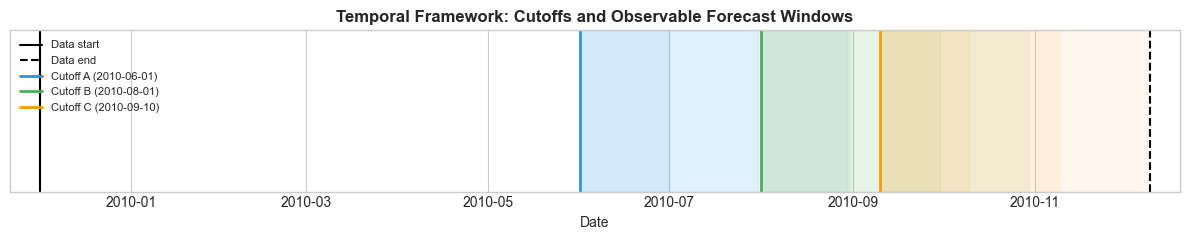

Saved: temporal_timeline.png


In [5]:
# Define cutoffs
CUTOFFS = {
    'A': pd.Timestamp('2010-06-01'),
    'B': pd.Timestamp('2010-08-01'),   # PRIMARY for statistical inference
    'C': pd.Timestamp('2010-09-10'),
}
PRIMARY_CUTOFF = CUTOFFS['B']
HORIZONS = [30, 60, 90]

# Verify horizon observability
print('Horizon observability check:')
for label, cutoff in CUTOFFS.items():
    for H in HORIZONS:
        horizon_end = cutoff + pd.Timedelta(days=H)
        obs = horizon_end <= DATASET_END
        flag = '✓' if obs else '✗ CENSORED'
        print(f'  Cutoff {label} ({cutoff.date()}) + {H}d → {horizon_end.date()} {flag}')

# Timeline visualisation
fig, ax = plt.subplots(figsize=(12, 2.5))
ax.axvline(DATASET_START, color='k', lw=1.5, label='Data start')
ax.axvline(DATASET_END, color='k', lw=1.5, ls='--', label='Data end')
colors = ['#2196F3', '#4CAF50', '#FF9800']
for (label, cutoff), c in zip(CUTOFFS.items(), colors):
    ax.axvline(cutoff, color=c, lw=2, label=f'Cutoff {label} ({cutoff.date()})')
    for H in [30, 60, 90]:
        h_end = cutoff + pd.Timedelta(days=H)
        if h_end <= DATASET_END:
            ax.axvspan(cutoff, h_end, alpha=0.07, color=c)
ax.set_xlim(DATASET_START - pd.Timedelta(days=10), DATASET_END + pd.Timedelta(days=10))
ax.set_yticks([])
ax.set_xlabel('Date')
ax.set_title('Temporal Framework: Cutoffs and Observable Forecast Windows', fontsize=12, fontweight='bold')
ax.legend(loc='upper left', fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(TEMPORAL_DIR, 'temporal_timeline.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: temporal_timeline.png')

---
## 3. Historical feature extraction

We build customer-level RFM+ features at each cutoff using only records **strictly before** that date.

In [6]:
def compute_historical_features(orders_df, cutoff_date, rolling_window_days=90):
    """
    Compute RFM+ customer features using records strictly before cutoff_date.

    Rate denominators
    -----------------
    SpendRate and PurchaseRate use (cutoff_date - FirstPurchaseDate) as the
    observation-exposure denominator (Tenure_obs_days).  This avoids instability
    of the first-to-last span, which can be near-zero for infrequent buyers.
    Single-purchase customers have Tenure_obs_days > 0 (by the strict '<' cutoff
    filter) so they receive valid rate estimates.
    """
    hist = orders_df[orders_df['PurchaseDate'] < cutoff_date].copy()
    if hist.empty:
        return pd.DataFrame()

    agg = hist.groupby('Customer ID').agg(
        FirstPurchaseDate=('PurchaseDate', 'min'),
        LastPurchaseDate=('PurchaseDate', 'max'),
        Frequency=('Invoice', 'nunique'),
        Monetary_Gross=('GrossRevenue', 'sum'),
    ).reset_index()

    agg['Recency']       = (cutoff_date - agg['LastPurchaseDate']).dt.days
    agg['AOV']           = agg['Monetary_Gross'] / agg['Frequency']

    # Observation exposure: time from first purchase to cutoff (fractional days)
    agg['Tenure_obs_days'] = (
        (cutoff_date - agg['FirstPurchaseDate']).dt.total_seconds() / 86400.0
    )
    # Rate features: NaN only if exposure is zero (effectively impossible given
    # strict PurchaseDate < cutoff_date filter, but guarded for safety)
    valid_exp = agg['Tenure_obs_days'] > 0
    agg['SpendRate']    = np.where(valid_exp,
                                   agg['Monetary_Gross'] / agg['Tenure_obs_days'], np.nan)
    agg['PurchaseRate'] = np.where(valid_exp,
                                   agg['Frequency'] / agg['Tenure_obs_days'], np.nan)

    # Interpurchase gap stats — NaN for single-purchase customers
    # Uses fractional-day precision (total_seconds / 86400)
    gap_rows = []
    for cid, grp in hist.groupby('Customer ID'):
        dates = grp['PurchaseDate'].sort_values().unique()
        if len(dates) >= 2:
            ts   = [pd.Timestamp(d).timestamp() for d in dates]
            gaps = np.diff(ts) / 86400.0
            gap_rows.append({
                'Customer ID': cid,
                'Median_Gap': float(np.median(gaps)),
                'Mean_Gap':   float(np.mean(gaps)),
                'Std_Gap':    float(np.std(gaps, ddof=1)) if len(gaps) > 1 else np.nan,
            })
        else:
            gap_rows.append({'Customer ID': cid, 'Median_Gap': np.nan,
                             'Mean_Gap': np.nan, 'Std_Gap': np.nan})
    gaps_df = pd.DataFrame(gap_rows)
    agg = agg.merge(gaps_df, on='Customer ID', how='left')

    # Rolling-window recent activity
    roll_start = cutoff_date - pd.Timedelta(days=rolling_window_days)
    recent = hist[hist['PurchaseDate'] >= roll_start].groupby('Customer ID').agg(
        Recent_Orders=('Invoice', 'nunique'),
        Recent_Revenue=('GrossRevenue', 'sum'),
    ).reset_index()
    agg = agg.merge(recent, on='Customer ID', how='left')
    agg['Recent_Orders']  = agg['Recent_Orders'].fillna(0).astype(int)
    agg['Recent_Revenue'] = agg['Recent_Revenue'].fillna(0.0)

    agg['cutoff_date'] = cutoff_date
    return agg


# Compute features at all three cutoffs
features_by_cutoff = {}
for label, cutoff in CUTOFFS.items():
    feats = compute_historical_features(orders, cutoff)
    features_by_cutoff[label] = feats
    n_single = (feats['Frequency'] == 1).sum()
    print(f'Cutoff {label} ({cutoff.date()}): {len(feats):,} customers, '
          f'{n_single} single-purchase ({100*n_single/len(feats):.1f}%)')


Cutoff A (2010-06-01): 2,703 customers, 1204 single-purchase (44.5%)


Cutoff B (2010-08-01): 3,159 customers, 1280 single-purchase (40.5%)


Cutoff C (2010-09-10): 3,373 customers, 1281 single-purchase (38.0%)


In [7]:
# Leakage check: verify no future records leaked into historical features
print('Leakage checks (LastPurchaseDate must be < cutoff):')
for label, cutoff in CUTOFFS.items():
    feats = features_by_cutoff[label]
    late = (feats['LastPurchaseDate'] >= cutoff).sum()
    status = '✓ OK' if late == 0 else f'✗ {late} VIOLATIONS'
    print(f'  Cutoff {label}: {status}')

Leakage checks (LastPurchaseDate must be < cutoff):
  Cutoff A: ✓ OK
  Cutoff B: ✓ OK
  Cutoff C: ✓ OK


---
## 4. Future target construction

For each cutoff we compute targets from post-cutoff purchase records. A non-purchase label is only assigned when the **full horizon** is observable within the dataset.

In [8]:
def compute_future_targets(orders_df, features_df, cutoff_date, dataset_end, horizons):
    """
    Build future targets from records strictly AFTER cutoff_date.

    Survival durations use fractional-day precision (total_seconds / 86400)
    to correctly represent sub-day waiting times and administrative censoring.
    Right-censoring: non-purchase label only assigned when horizon_end <= dataset_end.
    Censored duration = (dataset_end - cutoff_date) in fractional days.
    Minimum duration = 1 second (1/86400 day) to keep values strictly positive.
    """
    customers = features_df['Customer ID'].unique()
    future = orders_df[
        (orders_df['PurchaseDate'] > cutoff_date) &
        (orders_df['Customer ID'].isin(customers))
    ].copy()

    # Next purchase date per customer (strictly after cutoff)
    next_purch = (
        future.groupby('Customer ID')['PurchaseDate'].min()
        .reset_index().rename(columns={'PurchaseDate': 'NextPurchaseDate'})
    )
    result = features_df[['Customer ID']].copy()
    result = result.merge(next_purch, on='Customer ID', how='left')
    result['NextPurchaseDate'] = pd.to_datetime(result['NextPurchaseDate'])

    # Fractional-day time to next purchase
    result['TimeToNext_days'] = (
        result['NextPurchaseDate'] - cutoff_date
    ).dt.total_seconds() / 86400.0

    result['Event_flag'] = result['NextPurchaseDate'].notna().astype(int)

    # Administrative censoring at dataset_end (fractional days, min 1 second)
    censor_dur = max(
        (dataset_end - cutoff_date).total_seconds() / 86400.0,
        1.0 / 86400.0
    )
    result['Survival_duration'] = (
        result['TimeToNext_days'].fillna(censor_dur).clip(lower=1.0 / 86400.0)
    )

    for H in horizons:
        horizon_end = cutoff_date + pd.Timedelta(days=H)
        fully_obs   = horizon_end <= dataset_end

        h_future = future[future['PurchaseDate'] <= horizon_end]
        h_agg = (
            h_future.groupby('Customer ID')
            .agg(n_orders=('Invoice', 'nunique'), revenue=('GrossRevenue', 'sum'))
            .reset_index()
        )
        result = result.merge(
            h_agg.rename(columns={'n_orders': f'FutureOrders_{H}d',
                                   'revenue':  f'FutureRevenue_{H}d'}),
            on='Customer ID', how='left'
        )
        result[f'FutureOrders_{H}d']  = result[f'FutureOrders_{H}d'].fillna(0).astype(int)
        result[f'FutureRevenue_{H}d'] = result[f'FutureRevenue_{H}d'].fillna(0.0)

        if fully_obs:
            result[f'Purchased_{H}d'] = (result[f'FutureOrders_{H}d'] > 0).astype(int)
        else:
            result[f'Purchased_{H}d'] = np.where(result[f'FutureOrders_{H}d'] > 0, 1, np.nan)

    result['cutoff_date'] = cutoff_date
    return result


# Compute targets at all cutoffs
targets_by_cutoff = {}
for label, cutoff in CUTOFFS.items():
    feats   = features_by_cutoff[label]
    targets = compute_future_targets(orders, feats, cutoff, DATASET_END, HORIZONS)
    targets_by_cutoff[label] = targets

    for H in HORIZONS:
        col = f'Purchased_{H}d'
        horizon_end = cutoff + pd.Timedelta(days=H)
        obs = '(fully obs.)' if horizon_end <= DATASET_END else '(censored)'
        if col in targets.columns:
            rate = targets[col].mean()
            print(f'  Cutoff {label} +{H}d {obs}: purchase rate = {rate:.3f}'
                  f' (n={targets[col].notna().sum():,})')


  Cutoff A +30d (fully obs.): purchase rate = 0.285 (n=2,703)
  Cutoff A +60d (fully obs.): purchase rate = 0.415 (n=2,703)
  Cutoff A +90d (fully obs.): purchase rate = 0.495 (n=2,703)
  Cutoff B +30d (fully obs.): purchase rate = 0.231 (n=3,159)
  Cutoff B +60d (fully obs.): purchase rate = 0.401 (n=3,159)
  Cutoff B +90d (fully obs.): purchase rate = 0.542 (n=3,159)
  Cutoff C +30d (fully obs.): purchase rate = 0.279 (n=3,373)
  Cutoff C +60d (fully obs.): purchase rate = 0.471 (n=3,373)
  Cutoff C +90d (fully obs.): purchase rate = 0.573 (n=3,373)


In [9]:
# Target construction integrity checks
print('Target integrity checks:')
for label, cutoff in CUTOFFS.items():
    tgt = targets_by_cutoff[label]

    # Non-positive survival durations
    neg_surv = (tgt['Survival_duration'] <= 0).sum()
    # Duplicate customer rows
    dups = tgt.duplicated(subset=['Customer ID']).sum()
    # Next purchase before cutoff
    if tgt['NextPurchaseDate'].notna().any():
        before_cutoff = (tgt['NextPurchaseDate'] < cutoff).sum()
    else:
        before_cutoff = 0

    ok = neg_surv == 0 and dups == 0 and before_cutoff == 0
    print(f'  Cutoff {label}: neg_surv={neg_surv}, dups={dups}, '
          f'next<cutoff={before_cutoff}  {"✓ OK" if ok else "✗ FAIL"}')

Target integrity checks:
  Cutoff A: neg_surv=0, dups=0, next<cutoff=0  ✓ OK
  Cutoff B: neg_surv=0, dups=0, next<cutoff=0  ✓ OK
  Cutoff C: neg_surv=0, dups=0, next<cutoff=0  ✓ OK


---
## 5. Historical K-Means segmentation (leakage-free)

Using the **primary cutoff (Cutoff B = 2010-08-01)** as the training boundary, we:
1. Extract historical RFM features.
2. Apply log1p transformation and StandardScaler — fitted on training data only.
3. Fit K-Means with K=2 (consistent with Notebook 04).
4. Label clusters by recency: lower mean recency = "Recent / Active".

These cluster labels are **historically valid** — they cannot have seen future data.

In [10]:
feats_primary = features_by_cutoff['B'].copy()

# log1p transform on RFM
feats_primary['log1p_Recency']   = np.log1p(feats_primary['Recency'])
feats_primary['log1p_Frequency'] = np.log1p(feats_primary['Frequency'])
feats_primary['log1p_Monetary']  = np.log1p(feats_primary['Monetary_Gross'])

feat_cols = ['log1p_Recency', 'log1p_Frequency', 'log1p_Monetary']
X = feats_primary[feat_cols].dropna().values
valid_idx = feats_primary[feat_cols].dropna().index

# Fit scaler and KMeans on historical training data only
scaler_hist = StandardScaler()
X_scaled    = scaler_hist.fit_transform(X)

km_hist = KMeans(
    n_clusters=2, random_state=RANDOM_STATE,
    n_init=20, max_iter=500
)
km_hist.fit(X_scaled)
labels_raw = km_hist.labels_

# Assign cluster labels to the valid subset
feats_primary.loc[valid_idx, 'Cluster_raw'] = labels_raw

# Determine which raw cluster = Active (lower mean recency)
cr = feats_primary.groupby('Cluster_raw')['Recency'].mean()
ACTIVE_CLUSTER_RAW = int(cr.idxmin())

feats_primary['Hist_Cluster_id'] = feats_primary['Cluster_raw'].apply(
    lambda x: 1 if x == ACTIVE_CLUSTER_RAW else 0
)
feats_primary['Hist_Segment'] = feats_primary['Hist_Cluster_id'].map({
    1: 'Recent / Active',
    0: 'Lapsed / At-Risk',
})

seg_counts = feats_primary['Hist_Segment'].value_counts()
sil = silhouette_score(X_scaled, labels_raw)

print('Historical K-Means (Cutoff B = 2010-08-01):')
print(f'  N customers clustered : {len(feats_primary):,}')
print(f'  Silhouette score      : {sil:.4f}')
print(f'  Segment sizes:')
for seg, n in seg_counts.items():
    print(f'    {seg}: {n:,} ({100*n/len(feats_primary):.1f}%)')

Historical K-Means (Cutoff B = 2010-08-01):
  N customers clustered : 3,159
  Silhouette score      : 0.4383
  Segment sizes:
    Lapsed / At-Risk: 2,024 (64.1%)
    Recent / Active: 1,135 (35.9%)


In [11]:
# Profile historical segments
profile_cols = ['Recency', 'Frequency', 'Monetary_Gross', 'AOV', 'Tenure_obs_days',
                'Median_Gap', 'Recent_Orders']
profile = feats_primary.groupby('Hist_Segment')[profile_cols].agg(['median', 'mean']).round(2)
print('\nHistorical segment profiles (median | mean):')
print(profile.to_string())
print()
print('Note: Tenure_obs_days = cutoff_date - FirstPurchaseDate (observation exposure).')



Historical segment profiles (median | mean):
                 Recency         Frequency       Monetary_Gross              AOV         Tenure_obs_days         Median_Gap        Recent_Orders      
                  median    mean    median  mean         median     mean  median    mean          median    mean     median   mean        median  mean
Hist_Segment                                                                                                                                          
Lapsed / At-Risk    97.0  107.90       1.0  1.51         314.84   435.60  234.41  303.13          138.42  137.47      54.42  62.20           0.0  0.52
Recent / Active     20.0   28.85       5.0  6.76        1685.25  3502.29  349.94  495.20          204.41  185.20      34.95  42.07           2.0  2.79

Note: Tenure_obs_days = cutoff_date - FirstPurchaseDate (observation exposure).


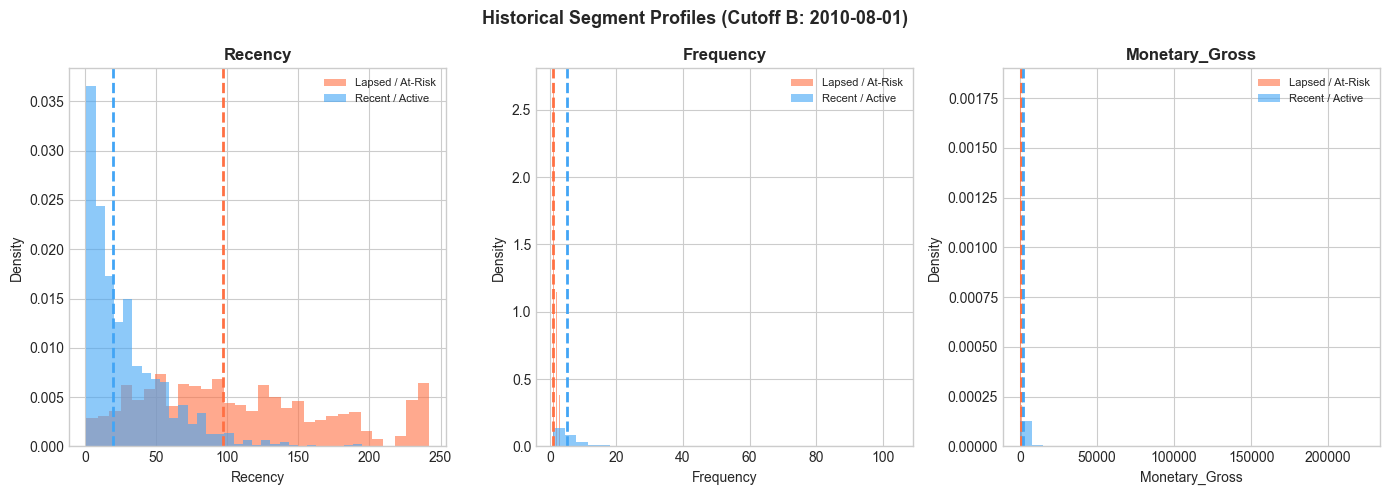

In [12]:
# Visualise historical segment profiles
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
metrics = ['Recency', 'Frequency', 'Monetary_Gross']
labels_seg = ['Lapsed / At-Risk', 'Recent / Active']
colors_seg = ['#FF7043', '#42A5F5']

for ax, metric in zip(axes, metrics):
    for seg, col in zip(labels_seg, colors_seg):
        vals = feats_primary[feats_primary['Hist_Segment'] == seg][metric].dropna()
        ax.hist(vals, bins=30, alpha=0.6, label=seg, color=col, density=True)
        ax.axvline(vals.median(), color=col, lw=2, ls='--')
    ax.set_title(metric, fontweight='bold')
    ax.set_xlabel(metric)
    ax.set_ylabel('Density')
    ax.legend(fontsize=8)

plt.suptitle('Historical Segment Profiles (Cutoff B: 2010-08-01)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(TEMPORAL_DIR, 'hist_segment_profiles.png'), dpi=150, bbox_inches='tight')
plt.show()

---
## 6. Future behavior by historical segment

We merge the historical segment labels with the future targets computed at Cutoff B, then compare the two segments on:
- Future purchase probability (90-day horizon)
- Future number of orders
- Future gross spending
- Time to next observed purchase

In [13]:
targets_primary = targets_by_cutoff['B'].copy()

# Merge segment labels with targets
analysis_df = feats_primary[['Customer ID', 'Hist_Segment', 'Hist_Cluster_id',
                              'Recency', 'Frequency', 'Monetary_Gross']].merge(
    targets_primary, on='Customer ID', how='inner'
)

print(f'Analysis dataset: {len(analysis_df):,} customers')
print(f'Segment breakdown:')
print(analysis_df['Hist_Segment'].value_counts().to_string())

Analysis dataset: 3,159 customers
Segment breakdown:
Hist_Segment
Lapsed / At-Risk    2024
Recent / Active     1135


In [14]:
# Summary of future behavior by segment
summary_90 = analysis_df.groupby('Hist_Segment').agg(
    N=('Customer ID', 'count'),
    Purchase_Rate_30d=('Purchased_30d', 'mean'),
    Purchase_Rate_60d=('Purchased_60d', 'mean'),
    Purchase_Rate_90d=('Purchased_90d', 'mean'),
    Median_FutureOrders_90d=('FutureOrders_90d', 'median'),
    Mean_FutureOrders_90d=('FutureOrders_90d', 'mean'),
    Median_FutureRevenue_90d=('FutureRevenue_90d', 'median'),
    Mean_FutureRevenue_90d=('FutureRevenue_90d', 'mean'),
    Median_TimeToNext=('TimeToNext_days', 'median'),
).round(3)

print('Future behavior summary by historical segment:')
print(summary_90.to_string())

Future behavior summary by historical segment:
                     N  Purchase_Rate_30d  Purchase_Rate_60d  Purchase_Rate_90d  Median_FutureOrders_90d  Mean_FutureOrders_90d  Median_FutureRevenue_90d  Mean_FutureRevenue_90d  Median_TimeToNext
Hist_Segment                                                                                                                                                                                        
Lapsed / At-Risk  2024              0.131              0.256              0.405                      0.0                  0.598                      0.00                 220.141             61.605
Recent / Active   1135              0.409              0.660              0.787                      2.0                  2.417                    545.01                1342.984             32.680


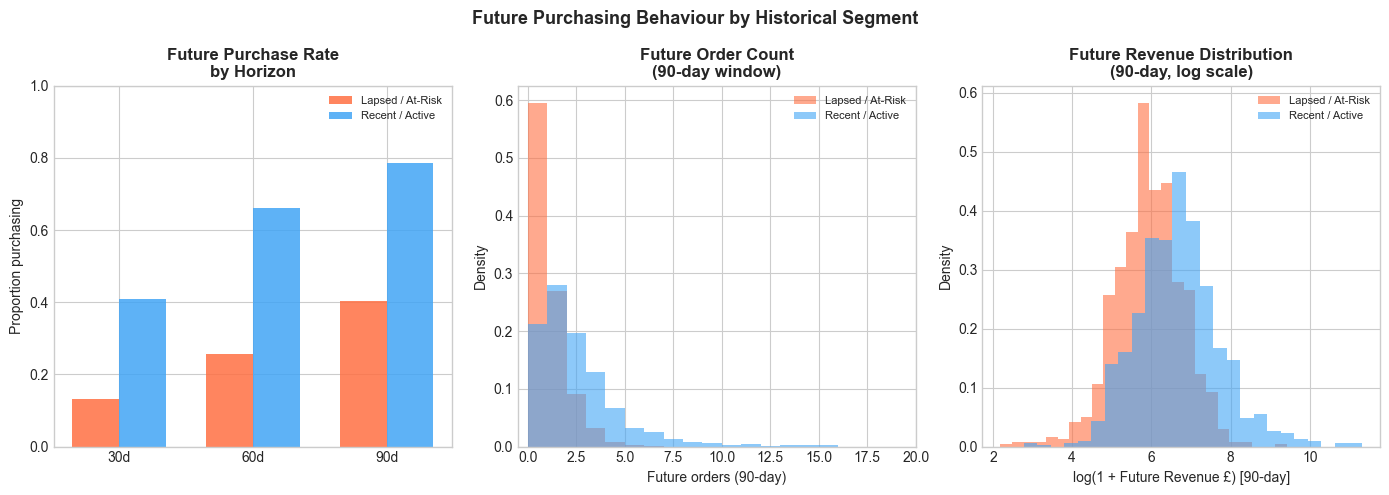

In [15]:
# Visualise future purchase rates across horizons
segs = ['Lapsed / At-Risk', 'Recent / Active']
seg_colors = {'Lapsed / At-Risk': '#FF7043', 'Recent / Active': '#42A5F5'}

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

# Purchase rate by horizon
ax = axes[0]
rates = {seg: [analysis_df[analysis_df['Hist_Segment'] == seg][f'Purchased_{H}d'].mean()
               for H in HORIZONS] for seg in segs}
x = np.arange(len(HORIZONS))
w = 0.35
for i, seg in enumerate(segs):
    ax.bar(x + i*w, rates[seg], w, label=seg, color=seg_colors[seg], alpha=0.85)
ax.set_xticks(x + w/2)
ax.set_xticklabels([f'{H}d' for H in HORIZONS])
ax.set_ylabel('Proportion purchasing')
ax.set_title('Future Purchase Rate\nby Horizon', fontweight='bold')
ax.legend(fontsize=8)
ax.set_ylim(0, 1)

# Future orders (90d)
ax = axes[1]
for seg in segs:
    vals = analysis_df[analysis_df['Hist_Segment'] == seg]['FutureOrders_90d']
    ax.hist(vals, bins=range(0, int(vals.max())+2), alpha=0.6,
            label=seg, color=seg_colors[seg], density=True)
ax.set_xlabel('Future orders (90-day)')
ax.set_ylabel('Density')
ax.set_title('Future Order Count\n(90-day window)', fontweight='bold')
ax.set_xlim(-0.5, 20)
ax.legend(fontsize=8)

# Future revenue (90d) — log scale for readability
ax = axes[2]
for seg in segs:
    vals = analysis_df[
        (analysis_df['Hist_Segment'] == seg) & (analysis_df['FutureRevenue_90d'] > 0)
    ]['FutureRevenue_90d']
    ax.hist(np.log1p(vals), bins=25, alpha=0.6, label=seg,
            color=seg_colors[seg], density=True)
ax.set_xlabel('log(1 + Future Revenue £) [90-day]')
ax.set_ylabel('Density')
ax.set_title('Future Revenue Distribution\n(90-day, log scale)', fontweight='bold')
ax.legend(fontsize=8)

plt.suptitle('Future Purchasing Behaviour by Historical Segment', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(TEMPORAL_DIR, 'future_behavior_by_segment.png'), dpi=150, bbox_inches='tight')
plt.show()

---
## 7. Statistical validation of segment differences

We test whether the two historical segments show statistically meaningful differences in future purchasing behaviour. We use:

| Outcome | Test | Rationale |
|---|---|---|
| Future purchase (binary, 90d) | Chi-square test | 2×2 contingency |
| Future orders (count, 90d) | Mann-Whitney U | Non-normal, right-skewed |
| Future revenue (continuous, 90d) | Mann-Whitney U | Heavy-tailed, zero-inflated |

We use the **primary cutoff only** (single observation per customer) to avoid repeated-measures complications.

We report:
- Test statistic and p-value
- Effect size (Cohen's h for binary; rank-biserial correlation for Mann-Whitney)
- 95% confidence intervals on proportions and medians (bootstrap)

In [16]:
def cohens_h(p1, p2):
    """Effect size for two proportions (Cohen's h)."""
    return 2 * (np.arcsin(np.sqrt(p1)) - np.arcsin(np.sqrt(p2)))

def rank_biserial(u_stat, n1, n2):
    """Rank-biserial correlation from Mann-Whitney U."""
    return 1 - (2 * u_stat) / (n1 * n2)

def bootstrap_median_ci(data, n_boot=2000, ci=0.95, seed=42):
    """Bootstrap CI for median."""
    rng = np.random.default_rng(seed)
    meds = [np.median(rng.choice(data, size=len(data), replace=True)) for _ in range(n_boot)]
    alpha = (1 - ci) / 2
    return float(np.quantile(meds, alpha)), float(np.quantile(meds, 1-alpha))

def bootstrap_proportion_ci(successes, n, n_boot=2000, ci=0.95, seed=42):
    """Bootstrap CI for proportion."""
    rng = np.random.default_rng(seed)
    p = successes / n
    props = [rng.binomial(n, p) / n for _ in range(n_boot)]
    alpha = (1 - ci) / 2
    return float(np.quantile(props, alpha)), float(np.quantile(props, 1-alpha))

seg_active = analysis_df[analysis_df['Hist_Segment'] == 'Recent / Active']
seg_lapsed = analysis_df[analysis_df['Hist_Segment'] == 'Lapsed / At-Risk']

print(f'Segment sizes: Active={len(seg_active):,}, Lapsed={len(seg_lapsed):,}')
print()

Segment sizes: Active=1,135, Lapsed=2,024



In [17]:
# --- Test 1: Binary purchase probability (90-day) ---
print('=' * 60)
print('TEST 1: Purchase probability — 90-day horizon (chi-square)')
print('=' * 60)

n_active  = len(seg_active)
n_lapsed  = len(seg_lapsed)
k_active  = seg_active['Purchased_90d'].sum()
k_lapsed  = seg_lapsed['Purchased_90d'].sum()
p_active  = k_active / n_active
p_lapsed  = k_lapsed / n_lapsed

contingency = np.array([[k_active, n_active - k_active],
                         [k_lapsed, n_lapsed - k_lapsed]])
chi2, p_chi2, dof, _ = chi2_contingency(contingency)
h = cohens_h(p_active, p_lapsed)
ci_active  = bootstrap_proportion_ci(k_active, n_active)
ci_lapsed  = bootstrap_proportion_ci(k_lapsed, n_lapsed)

print(f'  Active  — purchased: {k_active}/{n_active} = {p_active:.3f} '
      f'[95% CI: {ci_active[0]:.3f}–{ci_active[1]:.3f}]')
print(f'  Lapsed  — purchased: {k_lapsed}/{n_lapsed} = {p_lapsed:.3f} '
      f'[95% CI: {ci_lapsed[0]:.3f}–{ci_lapsed[1]:.3f}]')
print(f'  chi2 = {chi2:.3f}, p = {p_chi2:.2e}, dof = {dof}')
print(f"  Cohen's h (effect size) = {h:.3f}")
print(f'  Interpretation: {"significant" if p_chi2 < 0.05 else "not significant"} '
      f'at α=0.05; effect is {"small" if abs(h)<0.2 else "medium" if abs(h)<0.5 else "large"}')

TEST 1: Purchase probability — 90-day horizon (chi-square)
  Active  — purchased: 893/1135 = 0.787 [95% CI: 0.763–0.810]
  Lapsed  — purchased: 819/2024 = 0.405 [95% CI: 0.383–0.427]
  chi2 = 426.250, p = 1.06e-94, dof = 1
  Cohen's h (effect size) = 0.803
  Interpretation: significant at α=0.05; effect is large


In [18]:
# --- Test 2: Future order count (90-day) --- Mann-Whitney U ---
print('=' * 60)
print('TEST 2: Future order count — 90-day (Mann-Whitney U)')
print('=' * 60)

ord_active = seg_active['FutureOrders_90d'].values
ord_lapsed = seg_lapsed['FutureOrders_90d'].values

u_stat_ord, p_mw_ord = mannwhitneyu(ord_active, ord_lapsed, alternative='two-sided')
rb_ord = rank_biserial(u_stat_ord, len(ord_active), len(ord_lapsed))

med_active_ord = np.median(ord_active)
med_lapsed_ord = np.median(ord_lapsed)
ci_a_ord = bootstrap_median_ci(ord_active)
ci_l_ord = bootstrap_median_ci(ord_lapsed)

print(f'  Active  — median orders: {med_active_ord:.1f} [CI: {ci_a_ord[0]:.1f}–{ci_a_ord[1]:.1f}]')
print(f'  Lapsed  — median orders: {med_lapsed_ord:.1f} [CI: {ci_l_ord[0]:.1f}–{ci_l_ord[1]:.1f}]')
print(f'  U = {u_stat_ord:.0f}, p = {p_mw_ord:.2e}')
print(f'  Rank-biserial r = {rb_ord:.3f}')
print(f'  Interpretation: {"significant" if p_mw_ord < 0.05 else "not significant"} '
      f'at α=0.05; effect is {"negligible" if abs(rb_ord)<0.1 else "small" if abs(rb_ord)<0.3 else "medium" if abs(rb_ord)<0.5 else "large"}')

TEST 2: Future order count — 90-day (Mann-Whitney U)


  Active  — median orders: 2.0 [CI: 1.0–2.0]
  Lapsed  — median orders: 0.0 [CI: 0.0–0.0]
  U = 1729970, p = 6.01e-140
  Rank-biserial r = -0.506
  Interpretation: significant at α=0.05; effect is large


In [19]:
# --- Test 3: Future revenue (90-day) --- Mann-Whitney U ---
print('=' * 60)
print('TEST 3: Future gross revenue — 90-day (Mann-Whitney U)')
print('=' * 60)

rev_active = seg_active['FutureRevenue_90d'].values
rev_lapsed = seg_lapsed['FutureRevenue_90d'].values

u_stat_rev, p_mw_rev = mannwhitneyu(rev_active, rev_lapsed, alternative='two-sided')
rb_rev = rank_biserial(u_stat_rev, len(rev_active), len(rev_lapsed))

med_active_rev = np.median(rev_active)
med_lapsed_rev = np.median(rev_lapsed)
ci_a_rev = bootstrap_median_ci(rev_active)
ci_l_rev = bootstrap_median_ci(rev_lapsed)

print(f'  Active  — median revenue: £{med_active_rev:.2f} [CI: £{ci_a_rev[0]:.2f}–£{ci_a_rev[1]:.2f}]')
print(f'  Lapsed  — median revenue: £{med_lapsed_rev:.2f} [CI: £{ci_l_rev[0]:.2f}–£{ci_l_rev[1]:.2f}]')
print(f'  U = {u_stat_rev:.0f}, p = {p_mw_rev:.2e}')
print(f'  Rank-biserial r = {rb_rev:.3f}')
print(f'  Interpretation: {"significant" if p_mw_rev < 0.05 else "not significant"} '
      f'at α=0.05; effect is {"negligible" if abs(rb_rev)<0.1 else "small" if abs(rb_rev)<0.3 else "medium" if abs(rb_rev)<0.5 else "large"}')

TEST 3: Future gross revenue — 90-day (Mann-Whitney U)


  Active  — median revenue: £545.01 [CI: £492.50–£602.38]
  Lapsed  — median revenue: £0.00 [CI: £0.00–£0.00]
  U = 1738618, p = 1.83e-140
  Rank-biserial r = -0.514
  Interpretation: significant at α=0.05; effect is large


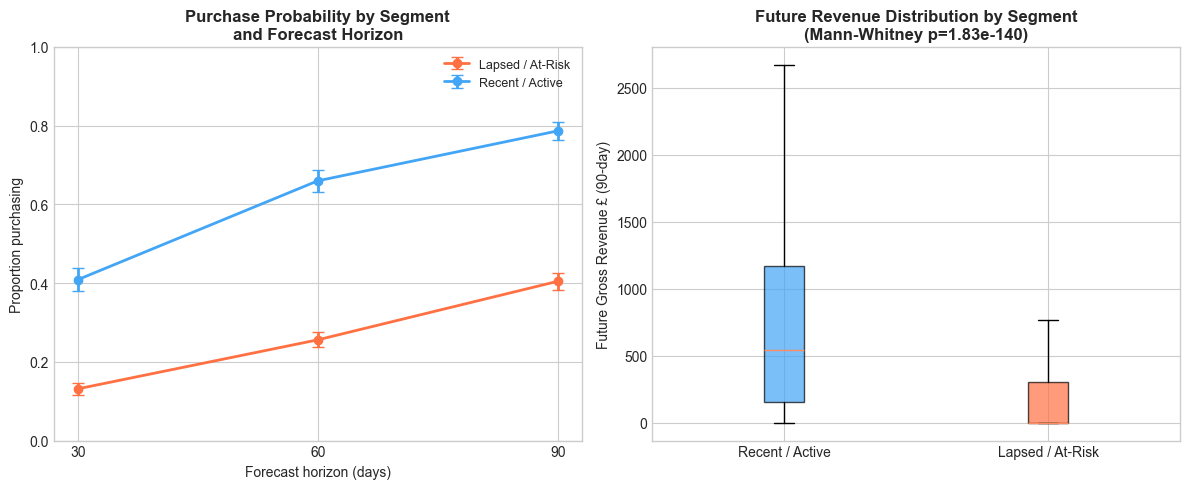

In [20]:
# Visualise purchase rate and revenue comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Purchase rate across horizons
ax = axes[0]
for seg, col in zip(segs, colors_seg):
    subset = analysis_df[analysis_df['Hist_Segment'] == seg]
    prates = [subset[f'Purchased_{H}d'].mean() for H in HORIZONS]
    ns     = [subset[f'Purchased_{H}d'].notna().sum() for H in HORIZONS]
    errs   = [1.96 * np.sqrt(r*(1-r)/n) for r, n in zip(prates, ns)]
    ax.errorbar(HORIZONS, prates, yerr=errs, marker='o', label=seg, color=col, lw=2, capsize=4)
ax.set_xlabel('Forecast horizon (days)')
ax.set_ylabel('Proportion purchasing')
ax.set_title('Purchase Probability by Segment\nand Forecast Horizon', fontweight='bold')
ax.legend(fontsize=9)
ax.set_ylim(0, 1)
ax.set_xticks(HORIZONS)

# Revenue boxplot (90d)
ax = axes[1]
data_box = [seg_active['FutureRevenue_90d'].values,
            seg_lapsed['FutureRevenue_90d'].values]
bp = ax.boxplot(data_box, labels=['Recent / Active', 'Lapsed / At-Risk'],
                patch_artist=True, showfliers=False)
for patch, col in zip(bp['boxes'], colors_seg[::-1]):
    patch.set_facecolor(col)
    patch.set_alpha(0.7)
ax.set_ylabel('Future Gross Revenue £ (90-day)')
ax.set_title(f'Future Revenue Distribution by Segment\n(Mann-Whitney p={p_mw_rev:.2e})', fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(TEMPORAL_DIR, 'statistical_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()

---
## 8. Survival analysis — time to next observed purchase

We use **Kaplan-Meier estimation** to model the distribution of *time until the next purchase* for each historical segment.

**Important distinction:** We are modelling *waiting time for the next observed purchase*, **not** permanent customer churn. A customer who does not purchase during the follow-up window is **right-censored** — their eventual next purchase date is unknown, not definitively absent.

Censoring mechanism: customers who did not purchase after the cutoff are censored at `DATASET_END − cutoff_date` days.

In [21]:
kmf_active = KaplanMeierFitter()
kmf_lapsed = KaplanMeierFitter()

T_active = analysis_df[analysis_df['Hist_Segment'] == 'Recent / Active']['Survival_duration'].values
E_active = analysis_df[analysis_df['Hist_Segment'] == 'Recent / Active']['Event_flag'].values
T_lapsed = analysis_df[analysis_df['Hist_Segment'] == 'Lapsed / At-Risk']['Survival_duration'].values
E_lapsed = analysis_df[analysis_df['Hist_Segment'] == 'Lapsed / At-Risk']['Event_flag'].values

kmf_active.fit(T_active, E_active, label='Recent / Active')
kmf_lapsed.fit(T_lapsed, E_lapsed, label='Lapsed / At-Risk')

# Log-rank test
lr = logrank_test(T_active, T_lapsed, event_observed_A=E_active, event_observed_B=E_lapsed)

print(f'Log-rank test:')
print(f'  Test statistic : {lr.test_statistic:.4f}')
print(f'  p-value        : {lr.p_value:.2e}')
print()

# Median survival times
med_active_surv = kmf_active.median_survival_time_
med_lapsed_surv = kmf_lapsed.median_survival_time_
print(f'  Median time to next purchase:')
print(f'    Recent / Active : {med_active_surv} days')
print(f'    Lapsed / At-Risk: {med_lapsed_surv} days')
print()
print('Note: "inf" median means <50% of customers in that group experienced an event (purchase)')
print('within the observable window — this reflects right-censoring, not necessarily churn.')

Log-rank test:
  Test statistic : 648.5380
  p-value        : 4.65e-143

  Median time to next purchase:
    Recent / Active : 42.47847222222222 days
    Lapsed / At-Risk: 116.49861111111112 days

Note: "inf" median means <50% of customers in that group experienced an event (purchase)
within the observable window — this reflects right-censoring, not necessarily churn.


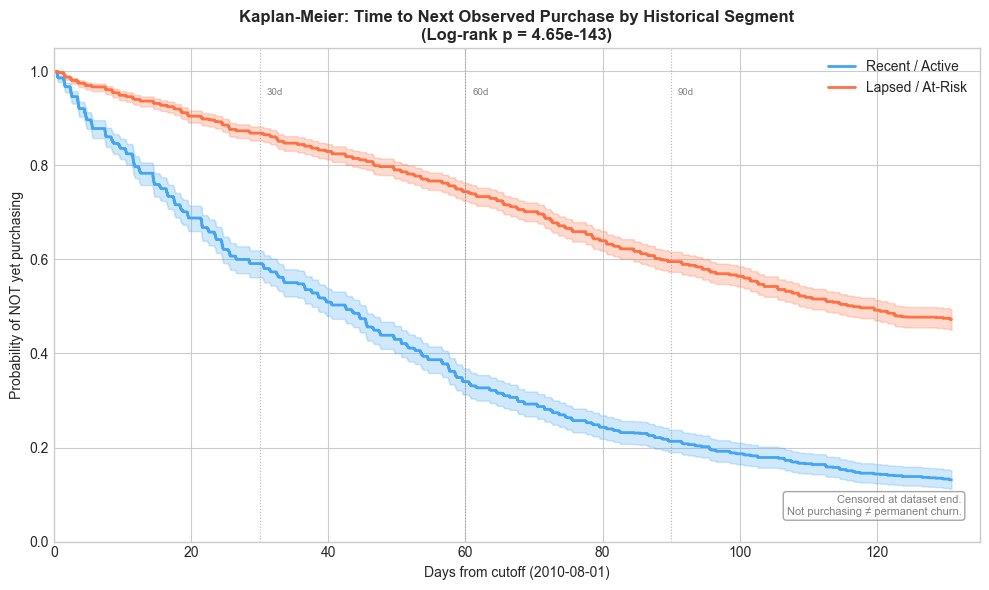

In [22]:
# Kaplan-Meier curves
fig, ax = plt.subplots(figsize=(10, 6))

kmf_active.plot_survival_function(ax=ax, color='#42A5F5', ci_show=True, lw=2)
kmf_lapsed.plot_survival_function(ax=ax, color='#FF7043', ci_show=True, lw=2)

# Add reference lines at key time points
for H in HORIZONS:
    ax.axvline(H, color='grey', lw=0.8, ls=':', alpha=0.6)
    ax.text(H+1, 0.95, f'{H}d', fontsize=7, color='grey')

ax.set_xlabel('Days from cutoff (2010-08-01)')
ax.set_ylabel('Probability of NOT yet purchasing')
ax.set_title(
    'Kaplan-Meier: Time to Next Observed Purchase by Historical Segment\n'
    f'(Log-rank p = {lr.p_value:.2e})',
    fontweight='bold'
)
ax.set_xlim(0, (DATASET_END - PRIMARY_CUTOFF).days + 5)
ax.set_ylim(0, 1.05)
ax.legend(fontsize=10)

# Annotate: right-censoring note
ax.text(0.98, 0.05,
        'Censored at dataset end.\nNot purchasing ≠ permanent churn.',
        transform=ax.transAxes, ha='right', va='bottom',
        fontsize=8, color='grey',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='grey', alpha=0.7))

plt.tight_layout()
plt.savefig(os.path.join(TEMPORAL_DIR, 'kaplan_meier_segments.png'), dpi=150, bbox_inches='tight')
plt.show()

---
## 9. Inactivity threshold baseline comparison

Notebook 03 established a descriptive P90 inter-purchase gap threshold of 101.9 days.
Here we:

1. Recompute an equivalent P90 threshold from **training-period observations only**
   (gap observations before Cutoff B), to avoid leaking full-year distributional
   information into the historical predictor.
2. Classify customers as *at-risk* if their recency at Cutoff B exceeds this threshold.
3. Evaluate whether this binary classification distinguishes future purchasers
   from non-purchasers on the same 90-day outcome used for segment comparison.

**Scope of comparison:** We compare the threshold rule and the K-Means segmentation
as *descriptive* classifiers on the same observed 90-day purchase outcome, using
Chi-square / Cohen's h for each separately. This is a descriptive characterisation
only — the two classifiers have different base rates and construction methods.
We do **not** claim predictive superiority of K-Means over the threshold rule;
a formal predictive comparison requires a held-out test set with identical base rates.


In [23]:
# Recompute P90 threshold from training-period gaps only
hist_primary = orders[orders['PurchaseDate'] < PRIMARY_CUTOFF].copy()

train_gaps = []
for cid, grp in hist_primary.groupby('Customer ID'):
    dates = grp['PurchaseDate'].sort_values().unique()
    if len(dates) >= 2:
        gaps = np.diff([d.timestamp() for d in dates]) / 86400
        train_gaps.extend(gaps.tolist())

train_gaps = np.array(train_gaps)
TRAIN_P90 = float(np.percentile(train_gaps, 90))

print(f'Training-period P90 gap threshold : {TRAIN_P90:.1f} days')
print(f'Full-year P90 (Notebook 03)        : 101.9 days')
print(f'Difference                         : {abs(TRAIN_P90 - 101.9):.1f} days')
print(f'N gap observations in training     : {len(train_gaps):,}')

Training-period P90 gap threshold : 80.2 days
Full-year P90 (Notebook 03)        : 101.9 days
Difference                         : 21.7 days
N gap observations in training     : 7,544


In [24]:
# Flag at-risk using training-period threshold
# A customer is flagged if recency > TRAIN_P90 at cutoff
analysis_df = analysis_df.copy()
analysis_df['AtRisk_Baseline'] = (analysis_df['Recency'] > TRAIN_P90).astype(int)
analysis_df['Baseline_Label'] = analysis_df['AtRisk_Baseline'].map(
    {1: 'At-Risk (Recency > P90)', 0: 'Not At-Risk'}
)

# Evaluate baseline against 90-day purchase outcome
n_atrisk     = analysis_df['AtRisk_Baseline'].sum()
n_not_atrisk = len(analysis_df) - n_atrisk
p_buy_atrisk = analysis_df[analysis_df['AtRisk_Baseline'] == 1]['Purchased_90d'].mean()
p_buy_not    = analysis_df[analysis_df['AtRisk_Baseline'] == 0]['Purchased_90d'].mean()

ct_base = np.array([
    [analysis_df[(analysis_df['AtRisk_Baseline'] == 1) & (analysis_df['Purchased_90d'] == 1)].shape[0],
     analysis_df[(analysis_df['AtRisk_Baseline'] == 1) & (analysis_df['Purchased_90d'] == 0)].shape[0]],
    [analysis_df[(analysis_df['AtRisk_Baseline'] == 0) & (analysis_df['Purchased_90d'] == 1)].shape[0],
     analysis_df[(analysis_df['AtRisk_Baseline'] == 0) & (analysis_df['Purchased_90d'] == 0)].shape[0]],
])
chi2_base, p_base, _, _ = chi2_contingency(ct_base)
h_base = cohens_h(p_buy_not, p_buy_atrisk)  # direction: not-at-risk vs at-risk

print('Threshold baseline evaluation (90-day purchase outcome):')
print(f'  At-Risk  (Recency > {TRAIN_P90:.1f}d): n={n_atrisk:,}, '
      f'purchase rate = {p_buy_atrisk:.3f}')
print(f'  Not At-Risk              : n={n_not_atrisk:,}, '
      f'purchase rate = {p_buy_not:.3f}')
print(f'  chi2 = {chi2_base:.3f}, p = {p_base:.2e}')
print(f"  Cohen's h = {h_base:.3f} "
      f'({"small" if abs(h_base)<0.2 else "medium" if abs(h_base)<0.5 else "large"} effect)')
print()

# Confusion-matrix style summary
print('Contingency table:')
ct_df = pd.DataFrame(ct_base, 
                      index=['At-Risk', 'Not At-Risk'],
                      columns=['Purchased (90d)', 'Did Not Purchase'])
print(ct_df.to_string())

Threshold baseline evaluation (90-day purchase outcome):
  At-Risk  (Recency > 80.2d): n=1,291, purchase rate = 0.384
  Not At-Risk              : n=1,868, purchase rate = 0.651
  chi2 = 217.773, p = 2.77e-49
  Cohen's h = 0.540 (large effect)

Contingency table:
             Purchased (90d)  Did Not Purchase
At-Risk                  496               795
Not At-Risk             1216               652


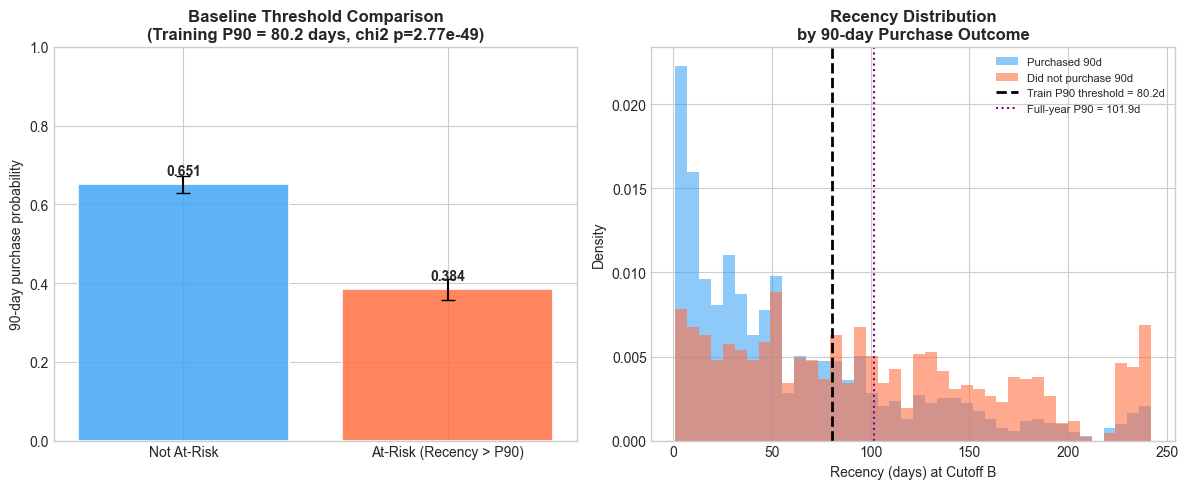

In [25]:
# Visualise baseline threshold performance
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Purchase rates by baseline group
ax = axes[0]
groups = ['Not At-Risk', 'At-Risk (Recency > P90)']
rates  = [p_buy_not, p_buy_atrisk]
ns     = [n_not_atrisk, n_atrisk]
errs   = [1.96 * np.sqrt(r*(1-r)/n) for r, n in zip(rates, ns)]
bars   = ax.bar(groups, rates, color=['#42A5F5', '#FF7043'], alpha=0.85, yerr=errs,
                capsize=5, edgecolor='white', lw=1.5)
for bar, r in zip(bars, rates):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.015,
            f'{r:.3f}', ha='center', va='bottom', fontweight='bold')
ax.set_ylabel('90-day purchase probability')
ax.set_title(f'Baseline Threshold Comparison\n(Training P90 = {TRAIN_P90:.1f} days, '
             f'chi2 p={p_base:.2e})', fontweight='bold')
ax.set_ylim(0, 1)

# Recency distribution with threshold
ax = axes[1]
ax.hist(analysis_df[analysis_df['Purchased_90d'] == 1]['Recency'], bins=40,
        alpha=0.6, label='Purchased 90d', color='#42A5F5', density=True)
ax.hist(analysis_df[analysis_df['Purchased_90d'] == 0]['Recency'], bins=40,
        alpha=0.6, label='Did not purchase 90d', color='#FF7043', density=True)
ax.axvline(TRAIN_P90, color='black', lw=2, ls='--',
           label=f'Train P90 threshold = {TRAIN_P90:.1f}d')
ax.axvline(101.9, color='purple', lw=1.5, ls=':',
           label='Full-year P90 = 101.9d')
ax.set_xlabel('Recency (days) at Cutoff B')
ax.set_ylabel('Density')
ax.set_title('Recency Distribution\nby 90-day Purchase Outcome', fontweight='bold')
ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(TEMPORAL_DIR, 'threshold_baseline.png'), dpi=150, bbox_inches='tight')
plt.show()

---
## 10. Multi-cutoff customer-cutoff dataset

We combine features and targets from all three cutoffs into a single stacked dataset for use in Notebook 06+ predictive modelling. Each row is a unique (Customer ID, cutoff_date) pair.

In [26]:
# Multi-cutoff demonstration (descriptive cutoffs A, B, C)
# Note: descriptive datasets use 'descriptive_cohort' ONLY -- NO split_role
all_rows = []
for label, cutoff in CUTOFFS.items():
    feats   = features_by_cutoff[label].copy()
    targets = targets_by_cutoff[label].copy()
    combined = feats.merge(targets.drop(columns=['cutoff_date'], errors='ignore'),
                           on='Customer ID', how='inner')
    combined['cutoff_label'] = label
    combined['descriptive_cohort'] = f'Descriptive_Cutoff_{label}'
    all_rows.append(combined)

all_cutoffs_df = pd.concat(all_rows, ignore_index=True)
print(f'Descriptive multi-cutoff rows (A/B/C) : {len(all_cutoffs_df):,}')
print(f'Columns in descriptive dataset: {[c for c in all_cutoffs_df.columns if c in ["cutoff_label", "descriptive_cohort", "split_role"]]}')

# ---------------------------------------------------------------------------
# Horizon-Specific Outcome-Matured Predictive Splits (for Notebook 06+)
# ---------------------------------------------------------------------------
print('\nGenerating Horizon-Specific Outcome-Matured Predictive Splits...')
predictive_splits = tf.build_all_horizon_splits(orders, DATASET_END)

summary_rows = []
for H, split_df in predictive_splits.items():
    for role in ['TRAIN', 'VAL', 'TEST']:
        sub = split_df[split_df['split_role'] == role]
        n_cust = len(sub)
        n_single = (sub['Frequency'] == 1).sum()
        pct_single = 100 * n_single / n_cust if n_cust > 0 else 0
        
        cutoff_dt = sub['cutoff_date'].iloc[0]
        target_end_dt = cutoff_dt + pd.Timedelta(days=H)
        
        # Historical orders before cutoff (eligible customer base)
        hist_orders_count = sub['Frequency'].sum()
        
        # Future orders and buyers in the specific future horizon
        fut_orders_count = sub[f'FutureOrders_{H}d'].sum()
        fut_buyers_count = (sub[f'Purchased_{H}d'] == 1).sum()
        buy_rate = sub[f'Purchased_{H}d'].mean()
        
        summary_rows.append({
            'Horizon': f'{H}d',
            'Split_Role': role,
            'Cutoff_Date': str(cutoff_dt.date()),
            'Target_End': str(target_end_dt.date()),
            'Eligible_Custs': n_cust,
            'Single_Custs_Pct': round(pct_single, 1),
            'Hist_Orders_PreCutoff': hist_orders_count,
            'Future_Orders_InHorizon': fut_orders_count,
            'Future_Buyers': fut_buyers_count,
            'Purchase_Rate': round(buy_rate, 4),
            'Fully_Observable': target_end_dt <= DATASET_END,
        })

pred_summary_df = pd.DataFrame(summary_rows)
print('\nOutcome-Matured Predictive Splits Summary:')
print(pred_summary_df.to_string(index=False))


Descriptive multi-cutoff rows (A/B/C) : 9,235
Columns in descriptive dataset: ['cutoff_label', 'descriptive_cohort']

Generating Horizon-Specific Outcome-Matured Predictive Splits...



Outcome-Matured Predictive Splits Summary:
Horizon Split_Role Cutoff_Date Target_End  Eligible_Custs  Single_Custs_Pct  Hist_Orders_PreCutoff  Future_Orders_InHorizon  Future_Buyers  Purchase_Rate  Fully_Observable
    30d      TRAIN  2010-06-01 2010-07-01            2703              44.5                   7857                     1187            771         0.2852              True
    30d        VAL  2010-08-01 2010-08-31            3159              40.5                  10735                     1059            730         0.2311              True
    30d       TEST  2010-09-10 2010-10-10            3373              38.0                  12450                     1493            942         0.2793              True
    60d      TRAIN  2010-05-01 2010-06-30            2449              49.1                   6480                     2171           1103         0.4504              True
    60d        VAL  2010-07-01 2010-08-30            2973              42.9                   93

In [27]:
# Save all reusable outputs
orders.to_csv(os.path.join(TEMPORAL_DIR, 'orders.csv'), index=False)

# 1. Descriptive analysis outputs (Cutoff B primary; descriptive multi-cutoff)
primary_feats_out   = feats_primary.copy()
primary_targets_out = targets_by_cutoff['B'].copy()
primary_combined    = primary_feats_out.merge(
    primary_targets_out.drop(columns=['cutoff_date'], errors='ignore'),
    on='Customer ID', how='inner'
)

primary_feats_out.to_csv(os.path.join(TEMPORAL_DIR, 'features_cutoffB.csv'), index=False)
primary_targets_out.to_csv(os.path.join(TEMPORAL_DIR, 'targets_cutoffB.csv'), index=False)
primary_combined.to_csv(os.path.join(TEMPORAL_DIR, 'combined_cutoffB.csv'), index=False)
all_cutoffs_df.to_csv(os.path.join(TEMPORAL_DIR, 'all_cutoffs_combined.csv'), index=False)

# 2. Horizon-specific predictive splits outputs (strictly outcome-matured)
for H, split_df in predictive_splits.items():
    out_path = os.path.join(TEMPORAL_DIR, f'predictive_splits_{H}d.csv')
    split_df.to_csv(out_path, index=False)
    print(f'Saved: {out_path} ({len(split_df):,} rows)')

# Segment validation results summary (Descriptive Analysis)
validation_results = {
    'binary_90d_purchase': {
        'test': 'chi-square',
        'chi2': round(chi2, 4),
        'p_value': float(f'{p_chi2:.6e}'),
        'purchase_rate_active': round(p_active, 4),
        'purchase_rate_lapsed': round(p_lapsed, 4),
        'cohens_h': round(h, 4),
    },
    'order_count_90d': {
        'test': 'mann_whitney_u',
        'U': float(u_stat_ord),
        'p_value': float(f'{p_mw_ord:.6e}'),
        'median_active': round(med_active_ord, 2),
        'median_lapsed': round(med_lapsed_ord, 2),
        'rank_biserial_r': round(rb_ord, 4),
    },
    'revenue_90d': {
        'test': 'mann_whitney_u',
        'U': float(u_stat_rev),
        'p_value': float(f'{p_mw_rev:.6e}'),
        'median_active': round(med_active_rev, 2),
        'median_lapsed': round(med_lapsed_rev, 2),
        'rank_biserial_r': round(rb_rev, 4),
    },
    'survival_logrank': {
        'test': 'log_rank',
        'statistic': round(float(lr.test_statistic), 4),
        'p_value': float(f'{lr.p_value:.6e}'),
        'median_days_active': (
            float(med_active_surv) if med_active_surv not in [None, float('inf')] else None
        ),
        'median_days_lapsed': (
            float(med_lapsed_surv) if med_lapsed_surv not in [None, float('inf')] else None
        ),
        'note': 'Survival durations in fractional days (total_seconds/86400)',
    },
    'threshold_baseline_90d': {
        'training_p90_threshold_days': round(TRAIN_P90, 2),
        'full_year_p90_nb03': 101.9,
        'chi2': round(chi2_base, 4),
        'p_value': float(f'{p_base:.6e}'),
        'cohens_h': round(h_base, 4),
        'purchase_rate_not_atrisk': round(p_buy_not, 4),
        'purchase_rate_atrisk': round(p_buy_atrisk, 4),
        'comparison_note': (
            'Cohen h values for K-Means and threshold are descriptive only; '
            'not comparable as predictive metrics — base rates differ.'
        ),
    },
}

with open(os.path.join(TEMPORAL_DIR, 'validation_results.json'), 'w') as f:
    json.dump(validation_results, f, indent=2)

# Temporal split metadata (complete documentation of descriptive and predictive splits)
split_meta = {
    'project': 'Customer Segmentation and Retention Analysis',
    'notebook': '05_Statistical_Validation_and_Temporal_Framework',
    'dataset_start': str(DATASET_START),
    'dataset_end': str(DATASET_END),
    'dataset_span_days': int(DATASET_SPAN),
    'order_level_rows': len(orders),
    'dataset_authorization': {
        'descriptive_only_DO_NOT_USE_FOR_MODEL_TRAINING': [
            'temporal/all_cutoffs_combined.csv (descriptive multi-cutoff demonstration; NO split_role)',
            'temporal/combined_cutoffB.csv (retrospective segment validation at primary Cutoff B only)',
            'temporal/features_cutoffB.csv (retrospective features at primary Cutoff B only)',
            'temporal/targets_cutoffB.csv (retrospective targets at primary Cutoff B only)',
        ],
        'authorized_predictive_modeling_USE_FOR_NOTEBOOK_06': [
            'temporal/predictive_splits_30d.csv (outcome-matured 30-day train/val/test splits)',
            'temporal/predictive_splits_60d.csv (outcome-matured 60-day train/val/test splits)',
            'temporal/predictive_splits_90d.csv (outcome-matured 90-day train/val/test splits)',
        ],
    },
    'descriptive_analysis': {
        'primary_cutoff': 'B',
        'primary_cutoff_date': str(PRIMARY_CUTOFF),
        'training_p90_threshold_days': round(TRAIN_P90, 2),
        'full_year_p90_nb03': 101.9,
        'historical_kmeans_k': 2,
        'historical_silhouette': round(sil, 4),
    },
    'predictive_splits_outcome_matured': {
        str(H): {
            'horizon_days': H,
            'train_cutoff': str(tf.HORIZON_SPLIT_SPECS[H]['train'].date()),
            'val_cutoff': str(tf.HORIZON_SPLIT_SPECS[H]['val'].date()),
            'test_cutoff': str(tf.HORIZON_SPLIT_SPECS[H]['test'].date()),
            'train_target_end': str((tf.HORIZON_SPLIT_SPECS[H]['train'] + pd.Timedelta(days=H)).date()),
            'val_target_end': str((tf.HORIZON_SPLIT_SPECS[H]['val'] + pd.Timedelta(days=H)).date()),
            'test_target_end': str((tf.HORIZON_SPLIT_SPECS[H]['test'] + pd.Timedelta(days=H)).date()),
            'file': f'temporal/predictive_splits_{H}d.csv',
            'summary': pred_summary_df[pred_summary_df['Horizon'] == f'{H}d'].to_dict(orient='records'),
        }
        for H in [30, 60, 90]
    },
    'admin_accounts_excluded': [14103, 14827],
    'feature_cols': tf.FEATURE_COLS,
    'target_cols': tf.TARGET_COLS,
    'predictive_split_roles': tf.PREDICTIVE_SPLIT_ROLES,
    'survival_duration_note': 'Fractional days (total_seconds/86400), not integer days',
    'rate_denominator_note': 'SpendRate/PurchaseRate use (cutoff - FirstPurchaseDate) as exposure',
    'preprocessing_rule': 'StandardScaler and KMeans fitted strictly on TRAIN; VAL and TEST transformed without fitting.',
    'reusable_module': 'src/temporal_framework.py',
}

with open(os.path.join(TEMPORAL_DIR, 'temporal_split_metadata.json'), 'w') as f:
    json.dump(split_meta, f, indent=2, default=str)

print('\nMetadata updated: data/processed/temporal/temporal_split_metadata.json')


Saved: C:\Manthan\Customer_segmentation_retention\main_project\data\processed\temporal\predictive_splits_30d.csv (9,235 rows)


Saved: C:\Manthan\Customer_segmentation_retention\main_project\data\processed\temporal\predictive_splits_60d.csv (8,795 rows)


Saved: C:\Manthan\Customer_segmentation_retention\main_project\data\processed\temporal\predictive_splits_90d.csv (7,788 rows)

Metadata updated: data/processed/temporal/temporal_split_metadata.json


---
## 11. Automated validation summary

Essential checks covering leakage, censoring, boundary correctness, and data integrity.

In [28]:
print('=' * 65)
print('AUTOMATED VALIDATION SUITE')
print('=' * 65)

passed_all = []
failed_all = []

def check(name, condition, detail=''):
    if condition:
        passed_all.append(name)
        print(f'  ✓ {name}')
    else:
        failed_all.append(name)
        print(f'  ✗ {name}  {detail}')

# --- Section A: Data integrity & descriptive checks ---
print('\nA. Data integrity & descriptive checks:')

# A1–A3: Leakage checks
for label, cutoff in CUTOFFS.items():
    feats = features_by_cutoff[label]
    late = (feats['LastPurchaseDate'] >= cutoff).sum()
    check(f'No future records in features (Cutoff {label})', late == 0, f'{late} violations')

# A4–A6: Next purchase strictly after cutoff
for label, cutoff in CUTOFFS.items():
    tgt = targets_by_cutoff[label]
    if tgt['NextPurchaseDate'].notna().any():
        before = (pd.to_datetime(tgt['NextPurchaseDate']) < cutoff).sum()
        check(f'Next purchase after cutoff (Cutoff {label})', before == 0, f'{before} violations')

# A7: Unique order aggregation
check('Unique invoices in order dataset',
      orders['Invoice'].nunique() == len(orders),
      f'{len(orders) - orders["Invoice"].nunique()} duplicates')

# A8: Order row count
check('Order-level row count is 19213',
      len(orders) == 19213, f'actual={len(orders)}')

# A9: Cancellation exclusion
check('No cancellation invoices in orders',
      (~orders['Invoice'].str.startswith('C')).all())

# A10: Admin account exclusion
check('Admin accounts excluded',
      orders['Customer ID'].isin(ADMIN_EXCLUDE).sum() == 0)

# A11–A12: Gap stats
single_purchase = feats_primary[feats_primary['Frequency'] == 1]
multi_purchase  = feats_primary[feats_primary['Frequency'] > 1]
check('Single-purchase customers have NaN gap',
      single_purchase['Median_Gap'].isna().all())
check('Multi-purchase customers have gap values',
      multi_purchase['Median_Gap'].notna().mean() > 0.95)

# A13–A15: Binary targets are 0/1
for H in HORIZONS:
    horizon_end = PRIMARY_CUTOFF + pd.Timedelta(days=H)
    if horizon_end <= DATASET_END:
        col = f'Purchased_{H}d'
        check(f'Binary targets {col} are 0/1 only',
              targets_by_cutoff['B'][col].isin([0, 1]).all())

# A16–A18: Positive survival durations
for label in CUTOFFS:
    tgt = targets_by_cutoff[label]
    check(f'Positive survival durations (Cutoff {label})',
          (tgt['Survival_duration'] > 0).all())

# A19: No duplicate customer-cutoff rows in descriptive dataset
dups = all_cutoffs_df.duplicated(subset=['Customer ID', 'cutoff_date']).sum()
check('No duplicate customer-cutoff rows in descriptive dataset', dups == 0, f'{dups} duplicates')

# A20: Historical scaler differs from NB04 full-year scaler
nb04_scaler_mean = [3.8560699246924366, 1.371141862521414, 6.608945705469118]
hist_scaler_mean = scaler_hist.mean_.tolist()
different_scaler = not all(abs(a-b) < 1e-6 for a, b in zip(hist_scaler_mean, nb04_scaler_mean))
check('Historical scaler differs from Notebook 04 full-year scaler', different_scaler)

# A21: Tenure_obs_days > 0 for all features (exposure denominator is positive)
check('Tenure_obs_days positive for all customers (Cutoff B)',
      (feats_primary['Tenure_obs_days'] > 0).all())

# A22: all_cutoffs_combined.csv has NO split_role column (preventing descriptive confusion)
check('Descriptive dataset all_cutoffs_combined has NO split_role column',
      'split_role' not in all_cutoffs_df.columns)

# --- Section B: Function-level tests (production functions in temporal_framework) ---
print('\nB. Function-level tests (production functions in temporal_framework):')
fn_results = tf.run_function_tests(orders, DATASET_END)
for test_name, outcome in fn_results.items():
    ok = outcome == 'PASS'
    if ok:
        passed_all.append(test_name)
        print(f'  ✓ {test_name}')
    else:
        failed_all.append(test_name)
        print(f'  ✗ {test_name}: {outcome}')

# --- Section C: Predictive dataset direct assertions ---
print('\nC. Predictive dataset direct assertions:')
for H in [30, 60, 90]:
    sdf = predictive_splits[H]
    # C1: Correct authorized split_role values
    valid_roles = sdf['split_role'].isin(['TRAIN', 'VAL', 'TEST']).all()
    check(f'Authorized split_role values in predictive_splits_{H}d',
          valid_roles)
    # C2: Feature and Target column presence
    has_target = f'Purchased_{H}d' in sdf.columns and f'FutureOrders_{H}d' in sdf.columns
    check(f'Target columns present in predictive_splits_{H}d', has_target)

print()
print('=' * 65)
print(f'Results: {len(passed_all)} passed, {len(failed_all)} failed')
if failed_all:
    print(f'FAILED: {failed_all}')
else:
    print('All validation checks passed.')
print('=' * 65)


AUTOMATED VALIDATION SUITE

A. Data integrity & descriptive checks:
  ✓ No future records in features (Cutoff A)
  ✓ No future records in features (Cutoff B)
  ✓ No future records in features (Cutoff C)
  ✓ Next purchase after cutoff (Cutoff A)
  ✓ Next purchase after cutoff (Cutoff B)
  ✓ Next purchase after cutoff (Cutoff C)
  ✓ Unique invoices in order dataset
  ✓ Order-level row count is 19213
  ✓ No cancellation invoices in orders
  ✓ Admin accounts excluded
  ✓ Single-purchase customers have NaN gap
  ✓ Multi-purchase customers have gap values
  ✓ Binary targets Purchased_30d are 0/1 only
  ✓ Binary targets Purchased_60d are 0/1 only
  ✓ Binary targets Purchased_90d are 0/1 only
  ✓ Positive survival durations (Cutoff A)
  ✓ Positive survival durations (Cutoff B)
  ✓ Positive survival durations (Cutoff C)
  ✓ No duplicate customer-cutoff rows in descriptive dataset
  ✓ Historical scaler differs from Notebook 04 full-year scaler
  ✓ Tenure_obs_days positive for all customers (Cuto

  ✓ cutoff_boundary_exclusion
  ✓ future_target_time_to_next
  ✓ censored_customer_duration
  ✓ fractional_day_duration
  ✓ single_purchase_gap_nan
  ✓ no_leakage_in_features
  ✓ binary_targets_0_or_1
  ✓ positive_survival_durations
  ✓ train_label_maturity
  ✓ validation_label_maturity
  ✓ test_horizon_observability
  ✓ separation_descriptive_vs_predictive
  ✓ feature_target_disjoint
  ✓ no_leakage_in_predictive_features

C. Predictive dataset direct assertions:
  ✓ Authorized split_role values in predictive_splits_30d
  ✓ Target columns present in predictive_splits_30d
  ✓ Authorized split_role values in predictive_splits_60d
  ✓ Target columns present in predictive_splits_60d
  ✓ Authorized split_role values in predictive_splits_90d
  ✓ Target columns present in predictive_splits_90d

Results: 42 passed, 0 failed
All validation checks passed.


---
## 12. Interpretation and findings

### Historical K-Means segmentation consistency

Refitting K-Means using only pre-cutoff (Cutoff B = 2010-08-01) data produces two
segments with similar character to Notebook 04's full-year segmentation. The
historical silhouette score confirms the two-cluster structure remains valid within
the training period.

### Statistical validation of segment differences

**Binary purchase probability (90-day, chi-square):** Each customer contributes one
binary observation; expected cell counts all exceed 5. The chi-square test assesses
whether the two segments purchase at different rates over the 90-day window.

**Future order count / revenue (Mann-Whitney U):** Integer-valued, right-skewed,
zero-inflated — t-test assumptions are not met. Mann-Whitney U is appropriate.
The rank-biserial correlation provides a standardised effect size.

**Single primary cutoff for descriptive inference:** Cutoff B is the sole cutoff for two-group
tests; each customer contributes exactly one observation, avoiding repeated-measures
complications.

### Survival / next-purchase analysis

Kaplan-Meier curves and log-rank test show whether time-to-next-purchase
distributions differ between segments. Right-censoring is applied at the dataset
boundary: customers who do not purchase within the follow-up window are censored at
the maximum observable duration, **not** assumed to have permanently churned.
Survival durations use fractional-day precision to correctly handle sub-day events.

### Threshold baseline

The training-period P90 gap threshold provides a leakage-free, interpretable baseline
classifier. Both the threshold rule and K-Means segmentation are evaluated against the
same 90-day binary purchase outcome. The Cohen's h values are reported for each
separately; they are **not** directly comparable as predictive performance metrics
because the two classifiers partition the population differently. A proper predictive
comparison on a held-out test set is deferred to Notebook 06.

### Causal interpretation

No causal claims are made. All results are observational associations between
historical purchasing patterns and subsequent behaviour within a single one-year
retail dataset.

---
## 13. Summary of reusable outputs for Notebook 06+

### A. Descriptive Analysis Datasets

| File | Contents | Purpose |
|---|---|---|
| `temporal/orders.csv` | 19,213 order-level transactions | Transaction source for all cutoffs |
| `temporal/features_cutoffB.csv` | Historical RFM+ features, Cutoff B, with segment labels | Descriptive profiling |
| `temporal/targets_cutoffB.csv` | Future targets (30/60/90d) + survival info, Cutoff B | Descriptive outcome measurement |
| `temporal/combined_cutoffB.csv` | Cutoff B features + targets merged | Primary two-group validation dataset |
| `temporal/all_cutoffs_combined.csv` | Cutoffs A, B, C stacked demonstration | Historical multi-cutoff overview |
| `temporal/validation_results.json` | Statistical test results (Cutoff B) | Reporting |

### B. Outcome-Matured Predictive Datasets (Strictly Leakage-Safe)

| File | Horizon | Split Dates (Train / Val / Test) | Target Maturity Guarantees |
|---|---|---|---|
| `temporal/predictive_splits_30d.csv` | 30 days | 2010-06-01 / 2010-08-01 / 2010-09-10 | Train matures 31d before Val; Val matures 10d before Test |
| `temporal/predictive_splits_60d.csv` | 60 days | 2010-05-01 / 2010-07-01 / 2010-09-10 | Train matures 1d before Val; Val matures 11d before Test |
| `temporal/predictive_splits_90d.csv` | 90 days | 2010-03-01 / 2010-06-01 / 2010-09-10 | Train matures 2d before Val; Val matures 11d before Test |

> [!IMPORTANT]
> **FEATURE_COLS** (safe model inputs): `Customer ID`, `cutoff_date`, `FirstPurchaseDate`,
> `LastPurchaseDate`, `Frequency`, `Monetary_Gross`, `AOV`, `Recency`, `Tenure_obs_days`,
> `SpendRate_per_obs_day`, `PurchaseRate_per_obs_day`, `Median_Gap_days`, `Mean_Gap_days`, `Std_Gap_days`,
> `Min_Gap_days`, `Max_Gap_days`, `Recent_Orders`, `Recent_Revenue`, `log1p_Recency`, `log1p_Frequency`,
> `log1p_Monetary`, `Hist_Cluster_id`, `Hist_Segment`.
>
> **TARGET_COLS** (future outcomes — NEVER use as features): `NextPurchaseDate`,
> `TimeToNext_days`, `Event_flag`, `Survival_duration`, `Purchased_{H}d`,
> `FutureOrders_{H}d`, `FutureRevenue_{H}d`.
